# A/B-тест формы оплаты ЖКХ

Команда запустила форму с автозаполнением реквизитов. Нужно понять, повысила ли она конверсию в успешную оплату.
Период теста — **1–30 апреля 2024 года**. Считаю A текущей формой, B новой.

Основную конверсию посчитаю по клиентам: **хотя бы раз успешно оплатили / открыли форму**.

План: посмотреть данные, обработать ошибки, построить воронку, проверить гипотезу и сформулировать рекомендацию.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

path = Path("../data/payments_ab.xlsx")
if not path.exists():
    path = Path("data/payments_ab.xlsx")

users = pd.read_excel(path, sheet_name="Пользователи")
payments = pd.read_excel(path, sheet_name="Платежи")
steps = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]

## 1. Разведочный анализ

In [2]:
print("Пользователи:", users.shape)
print("Платежи:", payments.shape)
display(users.head())
display(payments.head())

for name, df in [("Пользователи", users), ("Платежи", payments)]:
    print(name)
    display(pd.DataFrame({"Тип": df.dtypes, "Пропусков": df.isna().sum()}))
    print("Полных дубликатов:", df.duplicated().sum())

print("Повторов user_id в справочнике:", users.user_id.duplicated().sum())
print("Повторов payment_id:", payments.payment_id.duplicated().sum())
display(users.describe(include="all"))
display(payments[steps].agg(["min", "max"]))

Пользователи: (1504, 5)
Платежи: (2661, 7)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


Пользователи


,Тип,Пропусков
user_id,int64,0
group,str,1
age,int64,0
city,str,1
device_type,str,0


Полных дубликатов: 0
Платежи


,Тип,Пропусков
payment_id,int64,0
user_id,float64,1
group,str,0
step1_opened,datetime64[us],0
step2_entered,datetime64[us],405
step3_confirmed,datetime64[us],942
step4_success,datetime64[us],1139


Полных дубликатов: 0
Повторов user_id в справочнике: 0
Повторов payment_id: 0


,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


,step1_opened,step2_entered,step3_confirmed,step4_success
min,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
max,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


In [4]:
# Записи с пропусками или неправдоподобным возрастом
display(users[users.isna().any(axis=1) | ~users.age.between(0, 110)])
display(payments[payments.user_id.isna()])

print("Распределение числа попыток у одного клиента:")
display(payments.groupby("user_id").size().value_counts().sort_index().rename("Клиентов"))

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


Распределение числа попыток у одного клиента:


1    740
2    443
3    238
4     80
Name: Клиентов, dtype: int64

В файле **1 504 пользователя и 2 661 попытка**. Дубликатов нет.
Есть пользователь без группы, возраст −5 и 150, пропуск города и платёж без пользователя.
У клиента бывает от 1 до 4 попыток. Это не ошибка и не повод удалять клиента как выброс.

Возраст вне диапазона 0–110 заменю пропуском. Это проверка правдоподобия возраста,
а не ограничение на участие в тесте. Клиента без города сохраню.

## 2. Обработка некорректных записей

- Удаляю только полные дубли, если они есть. Разные записи с одним ID требуют отдельной проверки.
- Без пользователя или группы нельзя отнести платёж к эксперименту.
- Проверяю порядок шагов и время: следующий шаг не должен предшествовать предыдущему.
- Открытия должны попадать в апрель. События после конца месяца не считаю апрельскими успехами.
- Пропуски в конце воронки сохраняю как незавершённые попытки.

In [5]:
users_clean = users.drop_duplicates().copy()
payments_clean = payments.drop_duplicates().copy()
assert users_clean.user_id.notna().all() and users_clean.user_id.is_unique
assert payments_clean.payment_id.notna().all() and payments_clean.payment_id.is_unique

users_clean["age"] = users_clean.age.where(users_clean.age.between(0, 110))
users_clean["city"] = users_clean.city.fillna("Неизвестно")
users_clean = users_clean[users_clean.group.isin(["A", "B"])].copy()

data = payments_clean.merge(
    users_clean, on="user_id", how="left",
    suffixes=("_payment", ""), validate="many_to_one"
)

bad_date = pd.Series(False, index=data.index)
for step in steps:
    parsed = pd.to_datetime(data[step], errors="coerce", format="mixed")
    bad_date |= data[step].notna() & parsed.isna()
    data[step] = parsed

bad_order = pd.Series(False, index=data.index)
for previous, current in zip(steps, steps[1:]):
    bad_order |= data[current].notna() & (
        data[previous].isna() | data[current].lt(data[previous])
    )

checks = pd.DataFrame({
    "Нет пользователя или группы": data.user_id.isna() | data.group.isna(),
    "Некорректная группа платежа": ~data.group_payment.isin(["A", "B"]),
    "Конфликт группы": (data.group.notna() & data.group.ne(data.group_payment)).fillna(False),
    "Некорректная дата": bad_date,
    "Нарушен порядок шагов": bad_order,
    "Открытие не в апреле": ~data.step1_opened.between("2024-04-01", "2024-05-01", inclusive="left"),
})
display(checks.sum().rename("Количество"))

bad_rows = checks.any(axis=1)
display(data.loc[bad_rows, ["payment_id", "user_id", "group_payment", "group"]])
clean = data.loc[~bad_rows].copy()

# Сохраняем апрельское открытие, даже если завершение оказалось за пределами месяца.
for step in steps[1:]:
    clean.loc[clean[step] >= pd.Timestamp("2024-05-01"), step] = pd.NaT
clean["success"] = clean.step4_success.notna().astype(int)

print("Исключено попыток:", bad_rows.sum())
print("Осталось попыток:", len(clean))
print("Клиентов с открытием:", clean.user_id.nunique())

Нет пользователя или группы    1
Некорректная группа платежа    0
Конфликт группы                1
Некорректная дата              0
Нарушен порядок шагов          0
Открытие не в апреле           0
Name: Количество, dtype: int64

,payment_id,user_id,group_payment,group
2659,99002,1010.0,B,A
2660,99003,NaN,A,NaN


Исключено попыток: 2
Осталось попыток: 2659
Клиентов с открытием: 1501


Исключены две попытки: **99003** без пользователя и **99002** с конфликтом группы.
Осталось **2 659 попыток от 1 501 клиента**.

У пользователя без группы и двух клиентов с ошибочным возрастом нет попыток оплаты.
Двое последних остаются в справочнике назначений, но не входят в знаменатель «открыл форму».
Клиент без города остаётся в расчёте. Необычный номер платежа 99001 сам по себе не является ошибкой.

## 3. Сравнение групп

Проверю число назначенных клиентов, возраст, устройства и города.
Для проверки соотношения групп предполагаю сплит 50/50 — в реальном тесте эту настройку нужно подтвердить.

group
A    752
B    751
Name: Назначено клиентов, dtype: int64

Проверка сплита 50/50: p-value = 0.979


,count,mean,median
group,,,
A,751,32.74,32.0
B,750,32.65,33.0


device_type


group,A,B
device_type,,
android,54.3,49.1
ios,45.7,50.9


city


group,A,B
city,,
Москва,38.3,40.7
Неизвестно,0.1,0.0
Регион,35.6,32.8
СПб,25.9,26.5


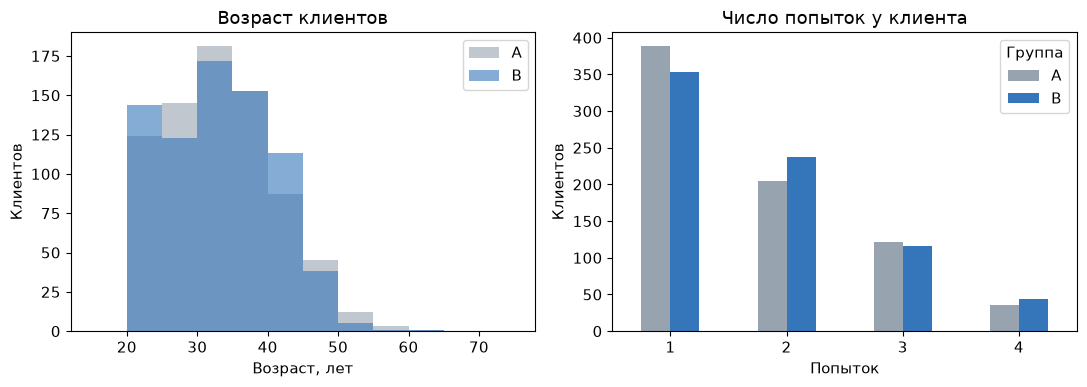

In [6]:
group_sizes = users_clean.groupby("group").size().reindex(["A", "B"])
display(group_sizes.rename("Назначено клиентов"))
srm = chisquare(group_sizes, f_exp=[group_sizes.sum() / 2] * 2)
print(f"Проверка сплита 50/50: p-value = {srm.pvalue:.3f}")
display(users_clean.groupby("group").age.agg(["count", "mean", "median"]).round(2))

for column in ["device_type", "city"]:
    print(column)
    display((pd.crosstab(users_clean[column], users_clean.group, normalize="columns") * 100).round(1))

attempts = clean.groupby(["user_id", "group"]).size().rename("attempts").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for group, color in [("A", "#98a3b0"), ("B", "#3476b9")]:
    axes[0].hist(users_clean.loc[users_clean.group.eq(group), "age"].dropna(),
                 bins=np.arange(15, 76, 5), alpha=0.6, color=color, label=group)
axes[0].set(title="Возраст клиентов", xlabel="Возраст, лет", ylabel="Клиентов")
axes[0].legend()
pd.crosstab(attempts.attempts, attempts.group).plot.bar(
    ax=axes[1], color=["#98a3b0", "#3476b9"], rot=0
)
axes[1].set(title="Число попыток у клиента", xlabel="Попыток", ylabel="Клиентов")
axes[1].legend(title="Группа")
plt.tight_layout()
plt.show()

Размеры групп почти одинаковые: **752 в A и 751 в B**, p-value проверки сплита около 0,98.
Средний возраст близок. Доля Android немного выше в A: **54,3% против 49,1%**.
Поэтому ниже отдельно посмотрю результат по устройствам.

Эти проверки не доказывают правильность случайного назначения.
Повторные попытки оставляю: они могут быть связаны с удобством формы.

## 4. Воронка оплаты

Сначала посмотрю воронку по попыткам. Проценты на графике — доля от всех открытий в соответствующей группе.
Переходы между соседними шагами посчитаю отдельно.

group,A,B
Открыли форму,1308,1351
Ввели реквизиты,1061,1194
Подтвердили платёж,758,960
Успешно оплатили,651,870


group,A,B
"Доля от открытий, %",,
Открыли форму,100.0,100.0
Ввели реквизиты,81.1,88.4
Подтвердили платёж,58.0,71.1
Успешно оплатили,49.8,64.4


group,A,B
"Переход с предыдущего шага, %",,
Открыли форму,NaN,NaN
Ввели реквизиты,81.1,88.4
Подтвердили платёж,71.4,80.4
Успешно оплатили,85.9,90.6


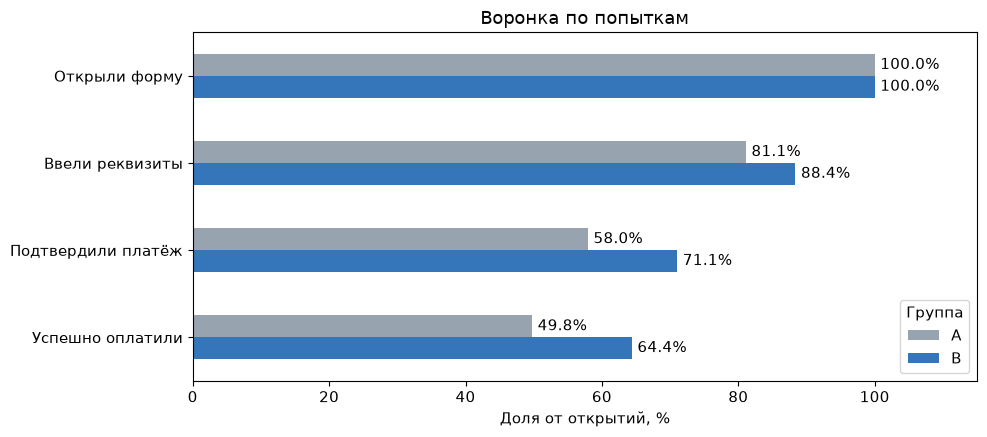

In [7]:
labels = ["Открыли форму", "Ввели реквизиты", "Подтвердили платёж", "Успешно оплатили"]
funnel = clean[steps].notna().groupby(clean.group).sum().T
funnel.index = labels
display(funnel)

funnel_pct = funnel.div(funnel.iloc[0]) * 100
display(funnel_pct.round(1).rename_axis("Доля от открытий, %"))
display((funnel.div(funnel.shift(1)) * 100).round(1).rename_axis("Переход с предыдущего шага, %"))

ax = funnel_pct.plot.barh(color=["#98a3b0", "#3476b9"], figsize=(10, 4.5))
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set(title="Воронка по попыткам", xlabel="Доля от открытий, %", ylabel="", xlim=(0, 115))
ax.legend(title="Группа")
plt.tight_layout()
plt.show()

По попыткам конверсия в успешную оплату составляет **49,8% в A и 64,4% в B**.
B выше на каждом переходе. Самая большая разница — между вводом реквизитов и подтверждением:
**71,4% против 80,4%**.

Переходы помогают найти место различий, но не доказывают отдельный причинный эффект на каждом шаге:
до поздних шагов могут доходить разные по составу клиенты.

## 5. Проверка основной гипотезы

Теперь одна строка — один клиент. Если у него была хотя бы одна успешная оплата за апрель, результат равен 1.

Продуктовая гипотеза: новая форма повышает конверсию.
Для статистической проверки:

- **H₀:** конверсия A равна конверсии B.
- **H₁:** конверсии различаются.

Использую **двусторонний z-тест двух долей**, уровень значимости 0,05.
Результат клиента бинарный, в группах достаточно успехов и неуспехов для нормального приближения.
Клиенты считаются независимыми при корректной рандомизации.
Проверка двусторонняя, чтобы учитывать изменение в обе стороны; положительная значимая разница поддержит гипотезу о росте.
Правила проверки следует выбирать до просмотра данных; здесь разбирается уже завершённый тест.

,Оплатили,Открыли форму,Конверсия
group,,,
A,493,751,0.656458
B,603,750,0.804000


Конверсия A: 65.65%, конверсия B: 80.40%
Разница B − A: 14.75 п.п.
Относительный рост: 22.5%
95% доверительный интервал: [10.33; 19.18] п.п.
p-value: 1.2e-10


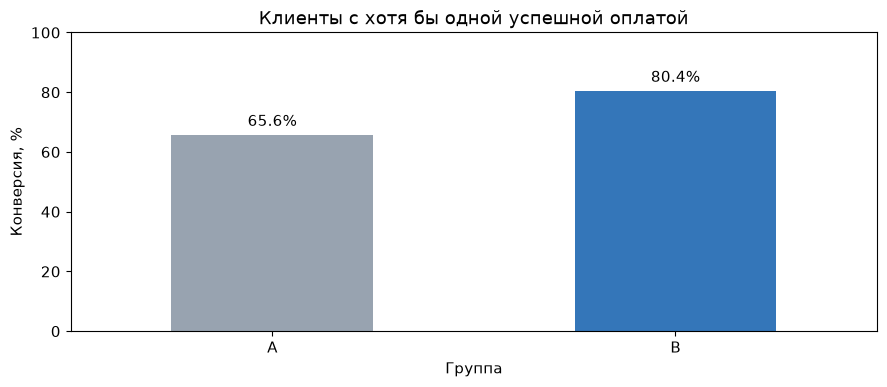

In [8]:
clients = clean.groupby(["user_id", "group"], as_index=False).agg(success=("success", "max"))
assert clients.user_id.is_unique

conversion = clients.groupby("group").success.agg(["sum", "count", "mean"]).reindex(["A", "B"])
conversion.columns = ["Оплатили", "Открыли форму", "Конверсия"]
display(conversion)

paid_a, n_a, rate_a = conversion.loc["A"]
paid_b, n_b, rate_b = conversion.loc["B"]
assert min(paid_a, paid_b, n_a - paid_a, n_b - paid_b) >= 5

z_stat, p_value = proportions_ztest(
    count=[paid_b, paid_a], nobs=[n_b, n_a], alternative="two-sided"
)
ci_low, ci_high = confint_proportions_2indep(
    paid_b, n_b, paid_a, n_a, method="wald", compare="diff", alpha=0.05
)
effect = rate_b - rate_a

print(f"Конверсия A: {rate_a:.2%}, конверсия B: {rate_b:.2%}")
print(f"Разница B − A: {effect * 100:.2f} п.п.")
print(f"Относительный рост: {effect / rate_a:.1%}")
print(f"95% доверительный интервал: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.")
print(f"p-value: {p_value:.3g}")

ax = (conversion["Конверсия"] * 100).plot.bar(color=["#98a3b0", "#3476b9"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
ax.set(title="Клиенты с хотя бы одной успешной оплатой", xlabel="Группа",
       ylabel="Конверсия, %", ylim=(0, 100))
plt.tight_layout()
plt.show()

Клиентская конверсия выросла с **65,6% до 80,4%**. Разница **+14,8 п.п.**, относительный рост **22,5%**.
95% доверительный интервал разницы — **от +10,3 до +19,2 п.п.**
P-value значительно ниже 0,05, поэтому нулевую гипотезу отвергаю.

P-value не показывает вероятность истинности H₀ и не измеряет пользу изменения.
Для решения важны также размер эффекта, доверительный интервал и качество данных.

## 6. Дополнительные проверки

### Спорная запись

Проверю два других решения: отнести спорный платёж к A по справочнику или исключить этого клиента целиком.
Это проверка устойчивости, а не выбор наиболее выгодного результата.

In [9]:
# Те же правила очистки, но конфликт группы сам по себе не исключает попытку.
other_errors = checks.drop(columns="Конфликт группы").any(axis=1)
alternative = data.loc[~other_errors].copy()
alternative["success"] = (
    alternative.step4_success.notna()
    & alternative.step4_success.lt(pd.Timestamp("2024-05-01"))
).astype(int)
conflict_ids = data.loc[checks["Конфликт группы"], "user_id"]

variants = {
    "Основной расчёт": clean,
    "Спорный платёж в A": alternative,
    "Без клиента с конфликтом": clean.loc[~clean.user_id.isin(conflict_ids)],
}
rows = []
for name, frame in variants.items():
    people = frame.groupby(["user_id", "group"], as_index=False).success.max()
    summary = people.groupby("group").success.agg(["sum", "count", "mean"])
    a, b = summary.loc["A"], summary.loc["B"]
    _, p = proportions_ztest([b["sum"], a["sum"]], [b["count"], a["count"]])
    rows.append([name, a["mean"] * 100, b["mean"] * 100, (b["mean"] - a["mean"]) * 100, p])

display(pd.DataFrame(rows, columns=["Вариант", "A, %", "B, %", "Разница, п.п.", "p-value"]))

,Вариант,"A, %","B, %","Разница, п.п.",p-value
0,Основной расчёт,65.645806,80.4,14.754194,1.202017e-10
1,Спорный платёж в A,65.778961,80.4,14.621039,1.703422e-10
2,Без клиента с конфликтом,65.733333,80.4,14.666667,1.529599e-10


Разница остаётся около **+14,6…+14,8 п.п.**: обработка одного спорного платежа не меняет вывод.

### Конверсия по попыткам

In [10]:
attempt_summary = clean.groupby(["group", "user_id"]).success.agg(["sum", "count"])
a = attempt_summary.loc["A"].to_numpy()
b = attempt_summary.loc["B"].to_numpy()
rng = np.random.default_rng(42)
differences = []

for _ in range(5000):
    sample_a = a[rng.integers(0, len(a), size=len(a))]
    sample_b = b[rng.integers(0, len(b), size=len(b))]
    rate_a_boot = sample_a[:, 0].sum() / sample_a[:, 1].sum()
    rate_b_boot = sample_b[:, 0].sum() / sample_b[:, 1].sum()
    differences.append(rate_b_boot - rate_a_boot)

attempt_conversion = clean.groupby("group").success.mean()
boot_ci = np.quantile(differences, [0.025, 0.975])
display((attempt_conversion * 100).rename("Конверсия по попыткам, %"))
print(f"Разница: {(attempt_conversion['B'] - attempt_conversion['A']) * 100:.2f} п.п.")
print(f"95% бутстрэп-интервал: [{boot_ci[0] * 100:.2f}; {boot_ci[1] * 100:.2f}] п.п.")

group
A    49.770642
B    64.396743
Name: Конверсия по попыткам, %, dtype: float64

Разница: 14.63 п.п.
95% бутстрэп-интервал: [10.96; 18.25] п.п.


По попыткам разница около **+14,6 п.п.**, её интервал тоже не включает ноль.
Вывод сохраняется при обеих трактовках конверсии. Бутстрэп здесь даёт интервал, отдельный p-value по нему не считаю.

### Устройства и города

Посмотрю на направление эффекта в срезах. Это описательная проверка: отдельные решения по сегментам
и выводы о различии эффектов между ними не делаю.

In [11]:
clients = clients.merge(
    users_clean[["user_id", "device_type", "city"]], on="user_id", validate="one_to_one"
)
for column in ["device_type", "city"]:
    print(column)
    segment = clients.pivot_table(index=column, columns="group", values="success", aggfunc="mean") * 100
    segment["B − A, п.п."] = segment["B"] - segment["A"]
    display(segment.round(1))

device_type


group,A,B,"B − A, п.п."
device_type,,,
android,64.4,79.9,15.6
ios,67.2,80.8,13.7


city


group,A,B,"B − A, п.п."
city,,,
Москва,62.5,81.0,18.5
Неизвестно,100.0,NaN,NaN
Регион,66.8,76.3,9.5
СПб,68.6,84.4,15.9


Рост наблюдается на обоих устройствах и в трёх городских категориях.
Для неизвестного города сравнение недоступно: там только один клиент из A.

## 7. Рекомендация

**Рекомендую поэтапно расширять запуск новой формы.** Клиентская конверсия выше на 14,8 п.п.,
а результат устойчив к обработке спорной записи и способу расчёта метрики.
При сохранении эффекта это примерно **148 дополнительных клиентов с оплатой на 1 000 открывших форму**.

Перед полным запуском стоит выяснить причину конфликта группы и подтвердить корректность сплита.
При расширении нужно следить за ошибочными и двойными списаниями, возвратами и обращениями в поддержку.
Этих показателей в файле нет, поэтому отсутствие побочных эффектов подтвердить нельзя.

Ограничения: только один месяц наблюдений, нет плана эксперимента и заранее выбранного минимального полезного эффекта.
Основной расчёт предполагает, что форма не влияет на сам факт открытия, а открытия логируются одинаково.
Пришедшие в конце месяца имеют меньше времени для повторных попыток; окна наблюдения должны быть сопоставимы.
Рост конверсии не доказывает, что ввод стал быстрее, и не позволяет оценить дополнительную выручку.